In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, roc_auc_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import plot_tree
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns

In [4]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### EDA

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [6]:
df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
df[['first_name', 'last_name']] = df['Name'].str.split(" ", expand=True)
df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)

In [7]:
df['group_size'] = df.groupby("group")['PassengerId'].transform('count')

In [8]:
df.groupby("group")[['HomePlanet']].nunique()\
    .sort_values(by=['HomePlanet'], ascending=False)

,HomePlanet
group,
9280,1
0001,1
0002,1
0003,1
0004,1
...,...
0303,0
0242,0
0251,0


In [9]:
df.groupby("group")[['last_name']].nunique().sort_values(by=['last_name'], ascending=False)

,last_name
group,
6302,4
0984,3
4005,3
3283,3
3862,3
...,...
0372,0
0190,0
0136,0


In [10]:
df.groupby(["HomePlanet", "Destination"]).count()

PassengerId  CryoSleep  Cabin   Age   VIP  \
HomePlanet Destination                                                
Earth      55 Cancri e            690        677    676   682   668   
           PSO J318.5-22          712        695    696   699   693   
           TRAPPIST-1e           3101       3018   3038  3034  3030   
Europa     55 Cancri e            886        861    854   862   870   
           PSO J318.5-22           19         19     18    19    19   
           TRAPPIST-1e           1189       1158   1161  1168  1163   
Mars       55 Cancri e            193        188    191   191   189   
           PSO J318.5-22           49         47     48    48    47   
           TRAPPIST-1e           1475       1440   1443  1437  1438   

                          RoomService  FoodCourt  ShoppingMall   Spa  VRDeck  \
HomePlanet Destination                                                         
Earth      55 Cancri e            680        671           673   676     673   
           PSO J318.5-22          694        699           694   697     701   
           TRAPPIST-1e           3027       3038          3028  3033    3019   
Europa     55 Cancri e            873        870           866   864     867   
           PSO J318.5-22           18         18            19    19      19   
           TRAPPIST-1e           1168       1162          1156  1167    1172   
Mars       55 Cancri e            188        191           184   190     189   
           PSO J318.5-22           47         48            49    48      48   
           TRAPPIST-1e           1447       1442          1449  1443    1441   

                          Name  Transported  group  num_in_group  first_name  \
HomePlanet Destination                                                         
Earth      55 Cancri e     672          690    690           690         672   
           PSO J318.5-22   695          712    712           712         695   
           TRAPPIST-1e    3032         3101   3101          3101        3032   
Europa     55 Cancri e     869          886    886           886         869   
           PSO J318.5-22    19           19     19            19          19   
           TRAPPIST-1e    1160         1189   1189          1189        1160   
Mars       55 Cancri e     186          193    193           193         186   
           PSO J318.5-22    49           49     49            49          49   
           TRAPPIST-1e    1443         1475   1475          1475        1443   

                          last_name  c_deck  c_num  c_side  group_size  
HomePlanet Destination                                                  
Earth      55 Cancri e          672     676    676     676         690  
           PSO J318.5-22        695     696    696     696         712  
           TRAPPIST-1e         3032    3038   3038    3038        3101  
Europa     55 Cancri e          869     854    854     854         886  
           PSO J318.5-22         19      18     18      18          19  
           TRAPPIST-1e         1160    1161   1161    1161        1189  
Mars       55 Cancri e          186     191    191     191         193  
           PSO J318.5-22         49      48     48      48          49  
           TRAPPIST-1e         1443    1443   1443    1443        1475

In [11]:
# 7   RoomService   8512 non-null   float64
#  8   FoodCourt     8510 non-null   float64
#  9   ShoppingMall  8485 non-null   float64
#  10  Spa           8510 non-null   float64
#  11  VRDeck        8505 non-null   float64
# df.loc[:, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']] = \
#     df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].fillna(0)
df['total_spent'] = df.loc[:, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  first_name    8493 non-null   str    
 17  last_name     8493 non-null   str    
 18  c_deck        8494 non-null   str    
 

In [12]:
df.groupby(["VIP", "CryoSleep"])[['total_spent']].agg(['mean', 'min', 'max', 'count'])

total_spent                    
                        mean  min      max count
VIP   CryoSleep                                 
False False      2160.761812  0.0  35987.0  5143
      True          0.000000  0.0      0.0  2941
True  False      4866.485714  0.0  31076.0   175
      True          0.000000  0.0      0.0    21

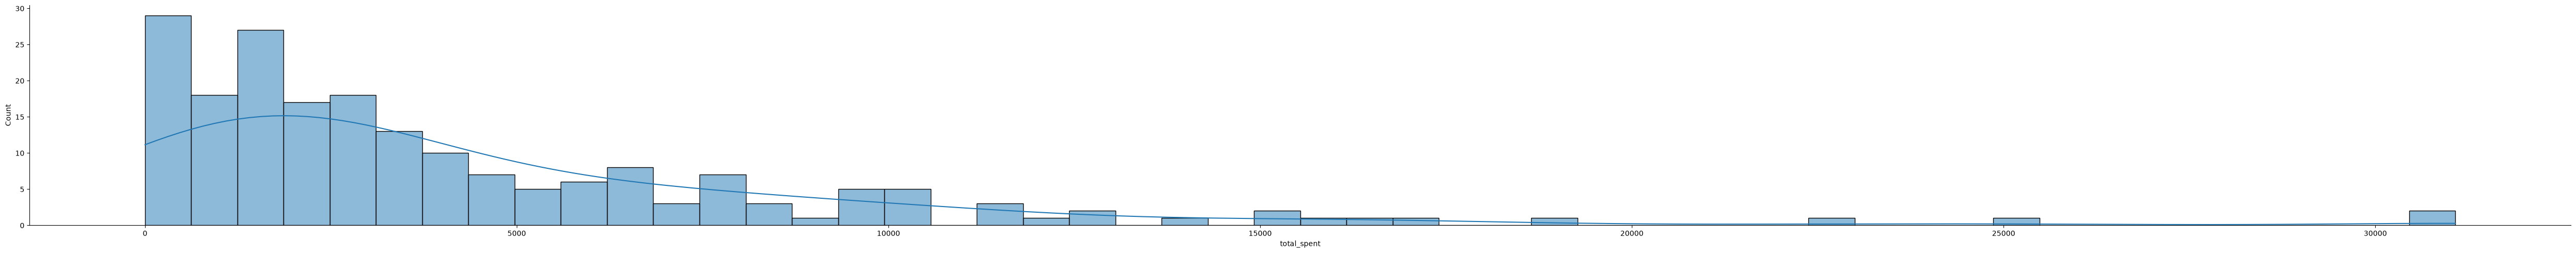

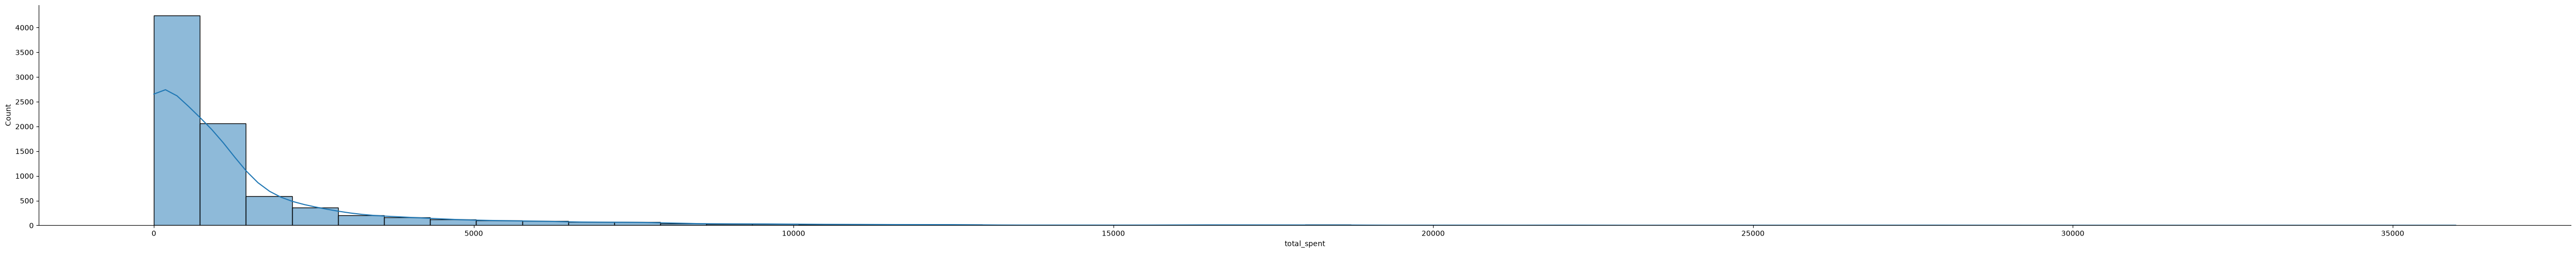

In [13]:
sns.displot(data=df[df['VIP']==True], x='total_spent', aspect=10, kde=True, bins=50);
plt.show()
sns.displot(data=df[df['VIP']==False], x='total_spent', aspect=10, kde=True, bins=50);
plt.show()

In [14]:
df[df['CryoSleep']&df['VIP']][['PassengerId', 'CryoSleep', 'VIP']]

,PassengerId,CryoSleep,VIP
365,0402_01,True,True
589,0612_01,True,True
1849,1976_03,True,True
2394,2572_02,True,True
2675,2866_01,True,True
3104,3349_01,True,True
4071,4348_01,True,True
4155,4441_01,True,True
4401,4668_02,True,True
4503,4786_01,True,True


In [15]:
df.groupby("CryoSleep")[['total_spent']].agg(['mean', 'min', 'max', 'count'])

total_spent                    
                  mean  min      max count
CryoSleep                                 
False      2248.299687  0.0  35987.0  5439
True          0.000000  0.0      0.0  3037

In [16]:
df['zero_spent'] = df['total_spent']==0
df.groupby(['CryoSleep', 'VIP', 'zero_spent']).size()

CryoSleep  VIP    zero_spent
False      False  False         4646
                  True           497
           True   False          168
                  True             7
True       False  True          2941
           True   True            21
dtype: int64

In [17]:
df[df['CryoSleep'].isna() & df['total_spent'] > 0][['PassengerId', 'CryoSleep', 'total_spent']].head(2)

,PassengerId,CryoSleep,total_spent
98,0105_01,NaN,703.0
104,0110_02,NaN,2018.0


In [18]:
df.loc[df['CryoSleep'].isna() & df['total_spent'] > 0, 'CryoSleep'] = False

In [19]:
df['CryoSleep'].value_counts()

CryoSleep
False    5558
True     3037
Name: count, dtype: int64

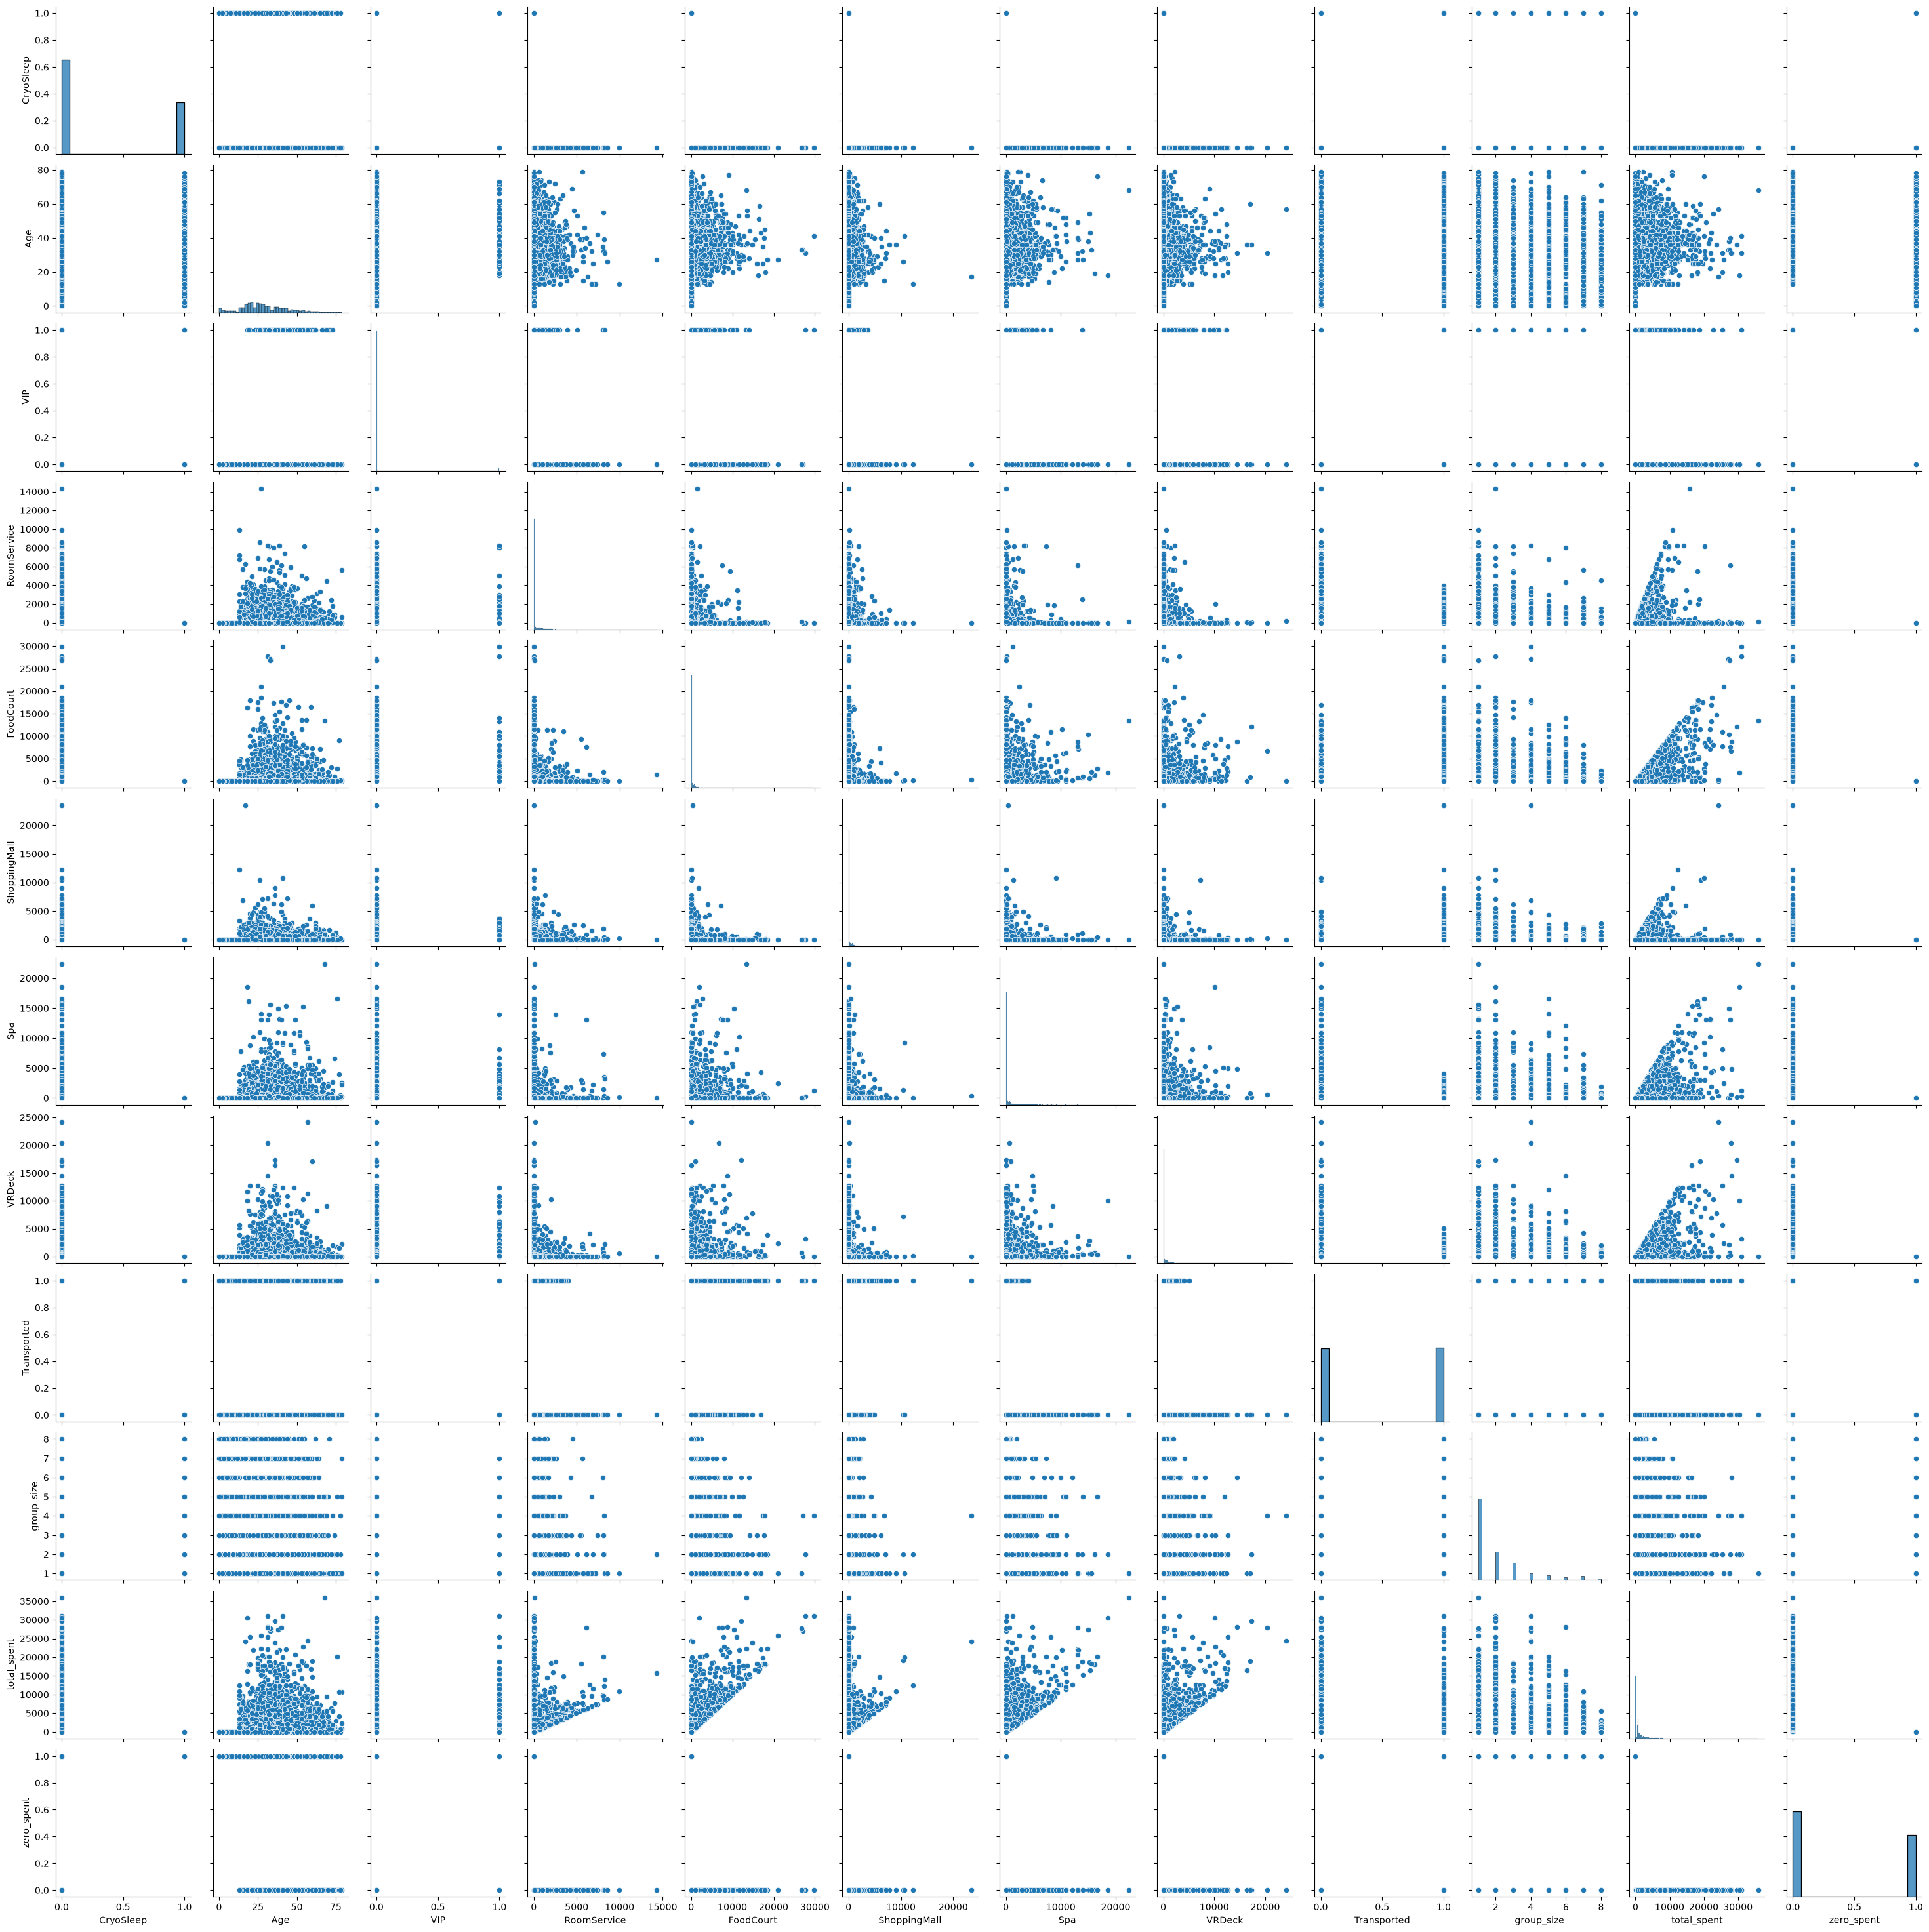

In [20]:
sns.pairplot(df)

In [21]:
df['HomePlanet'].isna().sum()

np.int64(201)

In [22]:
mask_no_home = df['HomePlanet'].isna()
df.loc[mask_no_home, 'HomePlanet'] = df.groupby('group')['HomePlanet']\
        .transform('first')[mask_no_home]

In [23]:
df['HomePlanet'].isna().sum()

np.int64(111)

In [24]:
gb_home = df.groupby('group')['HomePlanet'].nunique()
gb_home.value_counts()

HomePlanet
1    6107
0     110
Name: count, dtype: int64

In [25]:
gb_dst = df.groupby('group')['Destination'].nunique()
gb_dst.value_counts(normalize=True)

Destination
1    0.868104
2    0.107447
0    0.016567
3    0.007882
Name: proportion, dtype: float64

In [26]:
df[df['group']=='9280']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,group,num_in_group,first_name,last_name,c_deck,c_num,c_side,group_size,total_spent,zero_spent
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,...,9280,01,Celeon,Hontichre,E,608,S,2,4637.0,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,...,9280,02,Propsh,Hontichre,E,608,S,2,4826.0,False


In [27]:
gb_cryo = df.groupby('group')['CryoSleep'].nunique()
gb_cryo.value_counts(normalize=True)

CryoSleep
1    0.860705
2    0.133344
0    0.005951
Name: proportion, dtype: float64

In [28]:
df[df['Destination'].isna()]['group'].value_counts().sort_values(ascending=False)

group
0045    1
0138    1
0152    1
0382    1
0462    1
       ..
8956    1
9130    1
9195    1
9197    1
9226    1
Name: count, Length: 182, dtype: int64

In [68]:
df.groupby('c_deck')['Transported'].mean()
df.info()

<class 'pandas.DataFrame'>
Index: 8693 entries, 0 to 8692
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8582 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8590 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  c_deck        8494 non-null   str    
 17  c_num         8494 non-null   str    
 18  c_side        8594 non-null   str    
 19  g

In [69]:
to_plt = df[['Age', 'total_spent']].dropna()
plt.figure(figsize=(7,2))
plt.hist2d(x=to_plt['Age'], y=to_plt['total_spent'], bins=50)
plt.xlabel('Age')
plt.ylabel('Total spent')
plt.colorbar()
plt.show()

KeyError: "['total_spent'] not in index"

In [ ]:
df.groupby('group')[['c_deck', 'c_num', 'c_side']].nunique().sort_values('c_deck', ascending=False)

,c_deck,c_num,c_side
group,,,
3060,3,3,1
1709,3,3,1
0220,3,3,1
3236,3,3,1
0938,3,3,1
...,...,...,...
0327,0,0,0
0301,0,0,0
0239,0,0,0


In [ ]:
df['c_side'].isna().sum()

np.int64(199)

In [ ]:
mask_no_side = df['c_side'].isna()
df.loc[mask_no_side, 'c_side'] = df.groupby('group')['c_side']\
        .transform('first')[mask_no_side]

In [ ]:
df['c_side'].isna().sum()

np.int64(99)

In [ ]:
df[df['group_size']>1].groupby('group')[['c_deck']].nunique().value_counts()

c_deck
1         991
2         400
3          21
Name: count, dtype: int64

In [ ]:
df[df['group']=='3060']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,group,num_in_group,first_name,last_name,c_deck,c_num,c_side,group_size,total_spent,zero_spent
2831,3060_01,Mars,False,F/581/S,TRAPPIST-1e,13.0,False,760.0,2.0,2.0,...,3060,01,Rowl,Chman,F,581,S,3,764.0,False
2832,3060_02,Mars,False,D/98/S,TRAPPIST-1e,45.0,False,3309.0,0.0,10.0,...,3060,02,Duckes,Chman,D,98,S,3,3319.0,False
2833,3060_03,Mars,NaN,E/201/S,TRAPPIST-1e,55.0,False,0.0,0.0,0.0,...,3060,03,Torms,Chman,E,201,S,3,0.0,True


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8582 non-null   str    
 2   CryoSleep     8595 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  first_name    8493 non-null   str    
 17  last_name     8493 non-null   str    
 18  c_deck        8494 non-null   str    
 

In [ ]:
df['HomePlanet'].value_counts()

HomePlanet
Earth     4634
Europa    2161
Mars      1787
Name: count, dtype: int64

In [ ]:
from sklearn.impute import KNNImputer

cols_to_impute = ['Age']
knn = KNNImputer(n_neighbors=5).set_output(transform="pandas")
knn.fit_transform(pd.get_dummies(df[cols_to_impute])).loc[186]

Age    24.0
Name: 186, dtype: float64

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

df_known_age = df[df['Age'].notna()]
X = df_known_age[['total_spent']]
y = df_known_age['Age']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_pred_mean = np.zeros(len(y_test))
y_pred_mean.fill(y_train.median())

print('Mean age performance:', mean_squared_error(y_test, y_pred_mean), mean_absolute_error(y_test, y_pred_mean))

knnimpute_df = X.copy()
knnimpute_df['Age'] = y.values
knnimpute_df.loc[y_test.index, 'Age'] = np.nan
model_imp = KNNImputer(n_neighbors=100).set_output(transform='pandas')
model_imp.fit_transform(knnimpute_df)
y_pred_knn = model_imp.fit_transform(knnimpute_df).loc[y_test.index, 'Age']
print('knn age performance:', mean_squared_error(y_test, y_pred_knn), mean_absolute_error(y_test, y_pred_knn))

Mean age performance: 219.85320023487964 11.45742806811509
knn age performance: 207.47587733411623 11.35790369935408


In [ ]:
X = [[1, 2, 1], [3, 4, 2], [1, 6, np.nan], [1, 8, np.nan]]
imputer = KNNImputer(n_neighbors=2)
imputer.fit_transform(X)

array([[1. , 2. , 1. ],
       [3. , 4. , 2. ],
       [1. , 6. , 1.5],
       [1. , 8. , 1.5]])

### Feature Engineering

In [ ]:
# 1. every group has a the same home HomePlanet, c_side and Destination
# 2. VIP impute most frequent value
# 3. If CryoSleep unknown then CryoSleep = Unknown
# 4. c_side and c_deck add unknown if missing
# 5. total_spent = RoomService + FoodCourt + ShoppingMall + Spa + VRDeck
# 6. group_size = number of passengers in a group

In [ ]:
df = pd.read_csv('train.csv')
df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  c_deck        8494 non-null   str    
 17  c_num         8494 non-null   str    
 18  c_side        8494 non-null   str    
d

In [ ]:
def prep_data_for_sub_bad_for_submission(df):
    df = df.copy()
    df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
    df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)
    # 1. every group has a the same home planet and side
    mask_no_home = df['HomePlanet'].isna()
    df.loc[mask_no_home, 'HomePlanet'] = df.groupby('group')['HomePlanet']\
            .transform('first')[mask_no_home]
    mask_no_side = df['c_side'].isna()
    df.loc[mask_no_side, 'c_side'] = df.groupby('group')['c_side']\
            .transform('first')[mask_no_side]
    mask_no_side = df['Destination'].isna()
    df.loc[mask_no_side, 'Destination'] = df.groupby('group')['Destination']\
            .transform('first')[mask_no_side]

    # 6. group_size = number of passengers in a group
    df['group_size'] = df.groupby('group')['PassengerId'].transform('count')

    return df

def prep_data_for_sub_kaggle_cheating(df_train, df_test):
    df_train, df_test = df_train.copy(), df_test.copy()
    full = pd.concat([df_train, df_test], axis=0)
    full[['group', 'num_in_group']] = full['PassengerId'].str.split('_', expand=True)
    full[['c_deck', 'c_num', 'c_side']] = full['Cabin'].str.split("/", expand=True)
    # 1. every group has a the same home planet and side
    mask_no_home = full['HomePlanet'].isna()
    full.loc[mask_no_home, 'HomePlanet'] = full.groupby('group')['HomePlanet']\
            .transform('first')[mask_no_home]
    mask_no_side = full['c_side'].isna()
    full.loc[mask_no_side, 'c_side'] = full.groupby('group')['c_side']\
            .transform('first')[mask_no_side]
    mask_no_side = full['Destination'].isna()
    full.loc[mask_no_side, 'Destination'] = full.groupby('group')['Destination']\
            .transform('first')[mask_no_side]
    # 6. group_size = number of passengers in a group
    full['group_size'] = full.groupby('group')['PassengerId'].transform('count')
    df_train = full.loc[full['Transported'].notna()]
    df_test = full.loc[full['Transported'].isna()]
    df_train['Transported'] = df_train['Transported'].astype(bool)
    return df_train, df_test

df_train_, df_test_ = pd.read_csv('train.csv'), pd.read_csv('test.csv')
df_train_, df_test_ = prep_data_for_sub_kaggle_cheating(df_train_, df_test_)
df = df_train_

In [ ]:
home_dst_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
# probably la pah
cryo_deck_side_pipe = Pipeline([
    ('fn', FunctionTransformer(
        lambda x: x.astype(str), 
        feature_names_out="one-to-one")),
    # ('imputer', SimpleImputer(strategy='constant', fill_value='U')),
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
age_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
]) 

def add_total_spent(X):
    X = X.copy()
    exp_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'] 
    X['total_spent'] = X[exp_cols].sum(axis=1)
    exp_cols += ['total_spent']
    # log1p
    X = pd.DataFrame(np.log1p(X[exp_cols].values), columns=exp_cols, index=X.index)
    return X[exp_cols]

expences_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('fn', FunctionTransformer(
        add_total_spent, 
       feature_names_out=lambda self, i: ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'total_spent'])),
    ('scaler', StandardScaler())
]) 

feature_eng = ColumnTransformer([
    ('home', home_dst_pipe, ['HomePlanet', 'Destination']),
    ('unknown_imp_cat', cryo_deck_side_pipe, ['CryoSleep', 'c_deck', 'c_side']),
    ('age', age_pipe, ['Age']),
    ('expenses', expences_pipe, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']),
    ('group_size', 'passthrough', ['group_size'])
])
res = feature_eng.set_output(transform='pandas').fit_transform(df)
res.info()

<class 'pandas.DataFrame'>
Index: 8693 entries, 0 to 8692
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   home__HomePlanet_Earth            8693 non-null   float64
 1   home__HomePlanet_Europa           8693 non-null   float64
 2   home__HomePlanet_Mars             8693 non-null   float64
 3   home__Destination_55 Cancri e     8693 non-null   float64
 4   home__Destination_PSO J318.5-22   8693 non-null   float64
 5   home__Destination_TRAPPIST-1e     8693 non-null   float64
 6   unknown_imp_cat__CryoSleep_False  8693 non-null   float64
 7   unknown_imp_cat__CryoSleep_True   8693 non-null   float64
 8   unknown_imp_cat__c_deck_A         8693 non-null   float64
 9   unknown_imp_cat__c_deck_B         8693 non-null   float64
 10  unknown_imp_cat__c_deck_C         8693 non-null   float64
 11  unknown_imp_cat__c_deck_D         8693 non-null   float64
 12  unknown_imp_cat__c_dec

<Axes: >

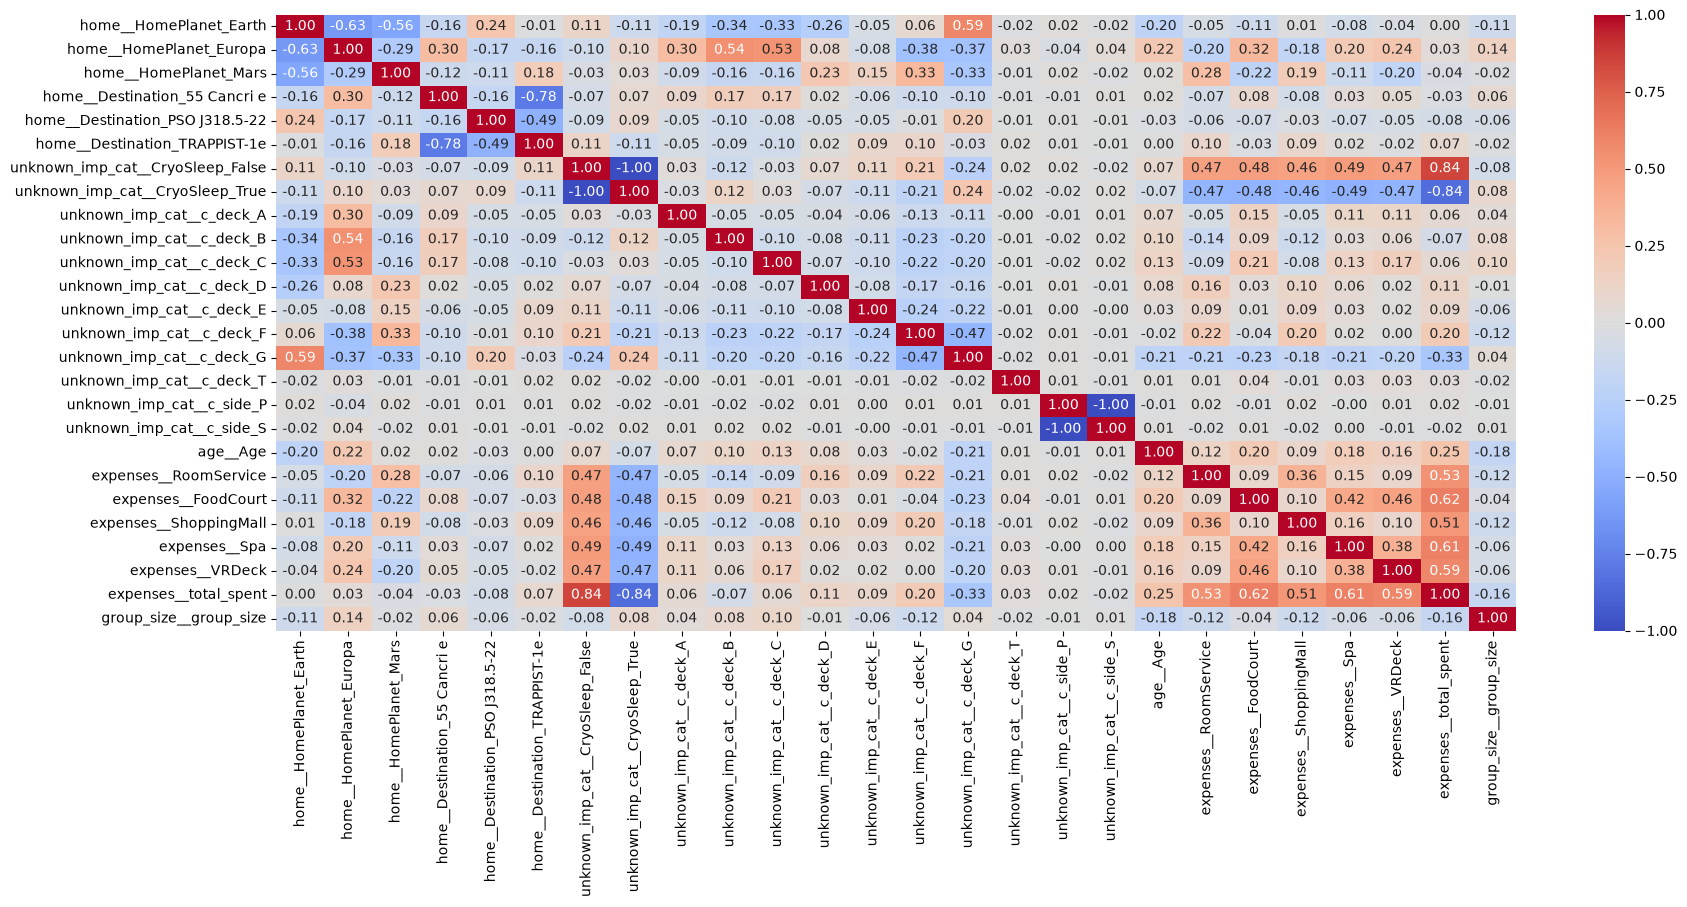

In [ ]:
plt.figure(figsize=(20, 8))
sns.heatmap(res.corr(), annot=True, fmt=".2f", cmap="coolwarm")

In [ ]:
X = df.drop(columns=['Transported'])
y = df['Transported']
X.shape, y.shape

((8693, 19), (8693,))

### Model Training

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"{X_train.shape[0]}, {X_test.shape[0]}")

6954, 1739


In [ ]:
def run_cv(model, X_train, y_train):
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"Cross-validation scores: {scores}")
    print(f"Average CV score: {scores.mean():.3f} (+/- {scores.std() * 2:.3f})")

In [ ]:
model_lr = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', LogisticRegression(max_iter=10000))
])
run_cv(model_lr, X_train, y_train)

Cross-validation scores: [0.75916607 0.77066858 0.77138749 0.78289001 0.79856115]
Average CV score: 0.777 (+/- 0.027)


In [ ]:
model_knn = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier(n_neighbors=20))
])
run_cv(model_knn, X_train, y_train)

Cross-validation scores: [0.77713875 0.77713875 0.78289001 0.77929547 0.78705036]
Average CV score: 0.781 (+/- 0.008)


In [ ]:
model_dt = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', DecisionTreeClassifier())
])
run_cv(model_dt, X_train, y_train)

Cross-validation scores: [0.7232207  0.71818835 0.73616104 0.74550683 0.73956835]
Average CV score: 0.733 (+/- 0.020)


In [ ]:
model_dt.named_steps['classifier']

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [ ]:
# model_dt.fit(X_train, y_train)
# plt.figure(figsize=(20,10))
# plot_tree(model_dt.named_steps['classifier'], filled=True, 
#           feature_names=model_dt.named_steps['feature_eng'].get_feature_names_out(), 
#           class_names=['Not Survived', 'Survived'])
# plt.show()

In [ ]:
model_dt = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', DecisionTreeClassifier(min_samples_split=600))
])
run_cv(model_dt, X_train, y_train)

Cross-validation scores: [0.74838246 0.78001438 0.76347951 0.76132279 0.78201439]
Average CV score: 0.767 (+/- 0.025)


In [ ]:
# model_dt.fit(X_train, y_train)
# plt.figure(figsize=(40,20))
# plot_tree(model_dt.named_steps['classifier'], filled=True, 
#           feature_names=model_dt.named_steps['feature_eng'].get_feature_names_out(), 
#           class_names=['Not Survived', 'Survived'])
# plt.savefig("decision_tree.png")

In [ ]:
# 1/0

#### Hyperparameter Tuning

In [ ]:
# knn
param_grid = {
    'classifier__n_neighbors': [30, 31, 32, 33, 34, 35, 40],
    'classifier__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}
model_knn_tune = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier())
])
grid_search = GridSearchCV(model_knn_tune, param_grid, cv=5, scoring='roc_auc', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)
best_params_knn = grid_search.best_params_

Fitting 5 folds for each of 112 candidates, totalling 560 fits


KeyboardInterrupt: 

In [ ]:
# Logistic Regression (scikit-learn >= 1.8)
# A list of grids prevents incompatible solver / regularization combinations.
# l1_ratio: 0 = L2, 1 = L1, values between 0 and 1 = elastic net.
# Smaller C means stronger regularization; C=np.inf disables regularization.
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
# Broader C range with half-decade steps; finer ratios near the previous best (0.9).
common_params_lr = {
    'classifier__C': np.logspace(-6, 6, 25),
    'classifier__class_weight': [None, 'balanced'],
    'classifier__fit_intercept': [True, False],
}

param_grid_lr = [
    {  # L2: supported by every solver.
        **common_params_lr,
        'classifier__solver': ['lbfgs', 'liblinear', 'sag', 'saga', 'newton-cholesky', 'newton-cg'],
        'classifier__l1_ratio': [0],
    },
    {  # L1: only liblinear and saga support it.
        **common_params_lr,
        'classifier__solver': ['liblinear', 'saga'],
        'classifier__l1_ratio': [1],
    },
    {  # Elastic net: only saga supports a mixture of L1 and L2.
        **common_params_lr,
        'classifier__solver': ['saga'],
        'classifier__l1_ratio': [0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99],
    },
    {  # No regularization: liblinear does not support C=np.inf.
        'classifier__C': [np.inf],
        'classifier__solver': ['lbfgs', 'sag', 'saga', 'newton-cholesky', 'newton-cg'],
        'classifier__l1_ratio': [0],
        'classifier__class_weight': [None, 'balanced'],
        'classifier__fit_intercept': [True, False],
    },
]

model_lr_tuned = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', LogisticRegression(max_iter=10000))
])

In [ ]:
search_lr = GridSearchCV(
    model_lr_tuned,
    param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1,
    error_score='raise',
)
# search_lr = RandomizedSearchCV(
#     model_lr_tuned,
#     param_distributions=param_grid_lr,
#     n_iter=500,
#     cv=5,
#     scoring='roc_auc',
#     n_jobs=-1,
#     verbose=1,
#     error_score='raise',
# )
search_lr.fit(X_train, y_train)
print("Best parameters (LR):", search_lr.best_params_)
print("Best cross-validation score (LR):", search_lr.best_score_)
best_params_lr = search_lr.best_params_

Fitting 5 folds for each of 1920 candidates, totalling 9600 fits


In [ ]:
# Decision Tree Classifier Tuning

param_dist_dt = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__splitter': ['best'],
    'classifier__max_depth': [6, 8 ,10, 12, 15, 20],#, 15, 17, 20],
    'classifier__min_samples_split': [20, 50, 70, 100, 120, 160, 200],
    'classifier__min_samples_leaf': [5, 10, 20, 50, 100, 150],
    # 'classifier__max_features': [None, 'sqrt', 'log2', 0.5, 0.75],
}

model_dt_tune = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', DecisionTreeClassifier())
])

# search_dt = RandomizedSearchCV(
#     model_dt_tune,
#     param_distributions=param_dist_dt,
#     cv=5,
#     n_iter=1000, 
#     scoring='roc_auc',
#     n_jobs=-1,
#     verbose=1,
#     error_score='raise',
# )

search_dt = GridSearchCV(
    model_dt_tune,
    param_grid=param_dist_dt,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1,
    error_score='raise',
)

search_dt.fit(X_train, y_train)
print("Best parameters (DT):", search_dt.best_params_)
print("Best cross-validation score (DT):", search_dt.best_score_)
best_params_dt = search_dt.best_params_
model_dt_tuned = search_dt.best_estimator_

Fitting 5 folds for each of 504 candidates, totalling 2520 fits
Best parameters (DT): {'classifier__criterion': 'entropy', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 120, 'classifier__splitter': 'best'}
Best cross-validation score (DT): 0.8730459729200936


In [ ]:
# Post-pruning: tune ccp_alpha while keeping the other best parameters.
# Include 0 (no pruning) and a broad logarithmic range of pruning strengths.
param_grid_dt_pruning = {
    'classifier__ccp_alpha': [0.0, *np.logspace(-6, -1, 26)],
}

grid_search_dt_pruning = GridSearchCV(
    model_dt_tuned,
    param_grid=param_grid_dt_pruning,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1,
    error_score='raise',
)
grid_search_dt_pruning.fit(X_train, y_train)
print("Best ccp_alpha:", grid_search_dt_pruning.best_params_['classifier__ccp_alpha'])
print("Best cross-validation score (pruned DT):", grid_search_dt_pruning.best_score_)
best_params_dt_pruned = {**best_params_dt, **grid_search_dt_pruning.best_params_}
model_dt_pruned = grid_search_dt_pruning.best_estimator_

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best ccp_alpha: 0.00039810717055349735
Best cross-validation score (pruned DT): 0.8732857295664758


In [ ]:
# Best Logistic Regression Model
# best_params_lr = {'classifier__C': np.float64(0.03162277660168379), 'classifier__class_weight': None, 'classifier__fit_intercept': True, 'classifier__l1_ratio': 0.8, 'classifier__solver': 'saga'}
model_lr_tuned = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', LogisticRegression(max_iter=10000))
]).set_params(**best_params_lr)
# Best KNN Model
# best_params_knn = {'classifier__algorithm': 'ball_tree', 'classifier__metric': 'manhattan', 'classifier__n_neighbors': 25, 'classifier__weights': 'uniform'}
model_knn_tuned = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier())
]).set_params(**best_params_knn)
# Best Decision Tree Model
# best_params_dt = {'classifier__class_weight': None, 'classifier__criterion': 'gini', 'classifier__max_depth': 20, 'classifier__max_features': None, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 100, 'classifier__splitter': 'best'}
# best_params_dt = {'classifier__criterion': 'gini', 'classifier__max_depth': 17, 'classifier__max_features': 0.75, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 100, 'classifier__splitter': 'best'}
best_params_dt = {'classifier__criterion': 'gini', 'classifier__max_depth': 10, 'classifier__max_features': None, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 100, 'classifier__splitter': 'best'}
model_dt_tuned = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', DecisionTreeClassifier())
]).set_params(**best_params_dt)


### Evaluation

In [ ]:
model_lr.fit(X_train, y_train)
model_knn.fit(X_train, y_train)
model_knn_tuned.fit(X_train, y_train)
model_lr_tuned.fit(X_train, y_train)
model_dt_tuned.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)
y_pred_knn = model_knn.predict(X_test)
y_pred_knn_tuned = model_knn_tuned.predict(X_test)
y_pred_lr_tuned = model_lr_tuned.predict(X_test)
y_pred_dt_tuned = model_dt_tuned.predict(X_test)

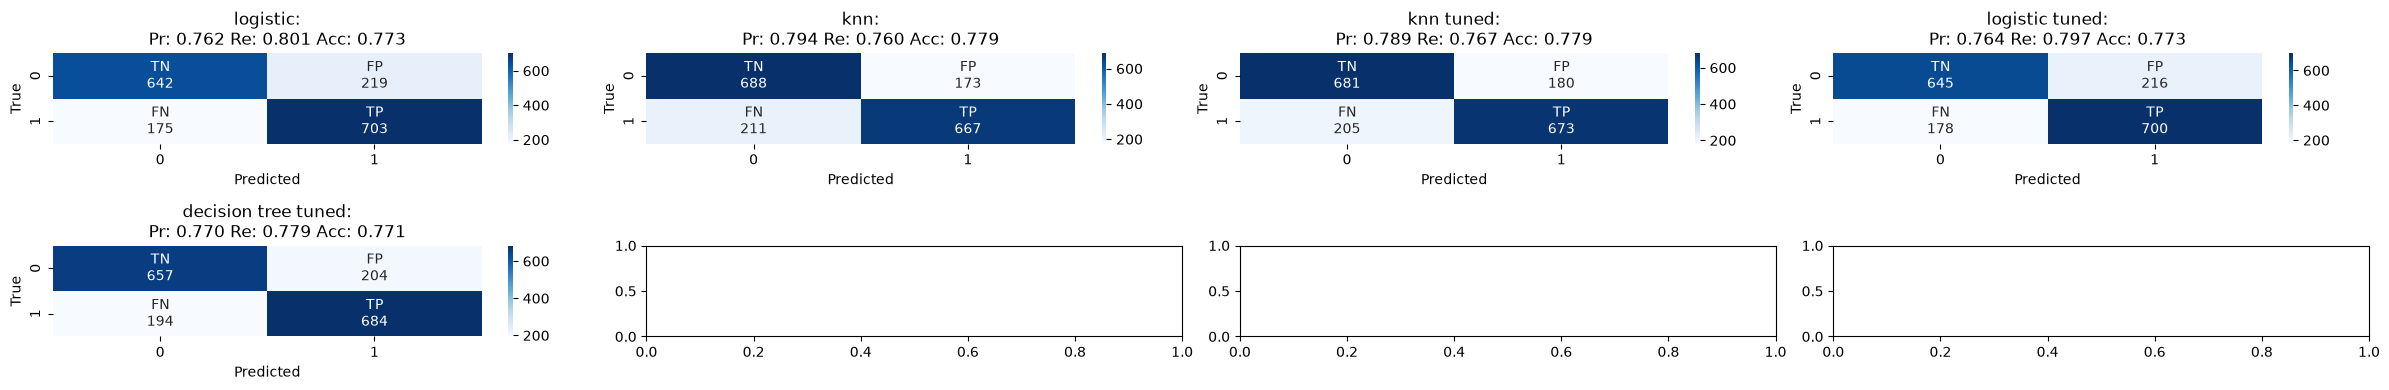

In [ ]:
def plot_confusion_matrix(y_true, y_pred, ax, label):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    annotations = np.array([[f'TN\n{cm[0, 0]}', f'FP\n{cm[0, 1]}'],
                            [f'FN\n{cm[1, 0]}', f'TP\n{cm[1, 1]}']])
    sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', ax=ax)
    precision_large, recall_large, accuracy_large = precision_score(y_true, y_pred), recall_score(y_true, y_pred), accuracy_score(y_true, y_pred)
    ax.set_title(f"""{label}:
    Pr: {precision_large:.3f} Re: {recall_large:.3f} Acc: {accuracy_large:.3f}""")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

fig, ax = plt.subplots(2, 4, figsize=(24, 4))
plot_confusion_matrix(y_test, y_pred_lr, ax[0, 0], "logistic")
plot_confusion_matrix(y_test, y_pred_knn, ax[0, 1], "knn")
plot_confusion_matrix(y_test, y_pred_knn_tuned, ax[0, 2], "knn tuned")
plot_confusion_matrix(y_test, y_pred_lr_tuned, ax[0, 3], "logistic tuned")
plot_confusion_matrix(y_test, y_pred_dt_tuned, ax[1, 0], "decision tree tuned")
plt.tight_layout()


$$
\text{Precision} = \frac{TP}{TP + FP}
$$
$$
\text{Recall} = \frac{TP}{TP + FN}
$$

In [ ]:
y_pred_dt_tuned, y_prob_dt_tuned = model_dt_tuned.predict(X_test), model_dt_tuned.predict_proba(X_test)[:, 1]
y_pred_rnd_proba = np.random.rand(y_test.shape[0])
df_th = pd.DataFrame({
    'probability': y_prob_dt_tuned,
    'th0.1': (y_prob_dt_tuned >= 0.1),
    'th0.2': (y_prob_dt_tuned >= 0.2),
    'th0.3': (y_prob_dt_tuned >= 0.3),
    'th0.4': (y_prob_dt_tuned >= 0.4),
    'th0.5': (y_prob_dt_tuned >= 0.5),
    'th0.6': (y_prob_dt_tuned >= 0.6),
    'th0.7': (y_prob_dt_tuned >= 0.7),
    'th0.8': (y_prob_dt_tuned >= 0.8),
    'th0.9': (y_prob_dt_tuned >= 0.9),
    'rnd0.1': (y_pred_rnd_proba >= 0.1),
    'rnd0.2': (y_pred_rnd_proba >= 0.2),
    'rnd0.3': (y_pred_rnd_proba >= 0.3),
    'rnd0.4': (y_pred_rnd_proba >= 0.4),
    'rnd0.5': (y_pred_rnd_proba >= 0.5),
    'rnd0.6': (y_pred_rnd_proba >= 0.6),
    'rnd0.7': (y_pred_rnd_proba >= 0.7),
    'rnd0.8': (y_pred_rnd_proba >= 0.8),
    'rnd0.9': (y_pred_rnd_proba >= 0.9)})
df_th

,probability,th0.1,th0.2,th0.3,th0.4,th0.5,th0.6,th0.7,th0.8,th0.9,rnd0.1,rnd0.2,rnd0.3,rnd0.4,rnd0.5,rnd0.6,rnd0.7,rnd0.8,rnd0.9
0,0.068493,False,False,False,False,False,False,False,False,False,True,True,False,False,False,False,False,False,False
1,0.802198,True,True,True,True,True,True,True,True,False,True,True,False,False,False,False,False,False,False
2,0.793103,True,True,True,True,True,True,True,False,False,True,True,True,False,False,False,False,False,False
3,0.566667,True,True,True,True,True,False,False,False,False,True,True,False,False,False,False,False,False,False
4,1.000000,True,True,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1734,0.745098,True,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False
1735,0.813953,True,True,True,True,True,True,True,True,False,True,True,True,True,False,False,False,False,False
1736,0.253968,True,True,False,False,False,False,False,False,False,True,True,True,True,True,True,True,True,True
1737,1.000000,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,False


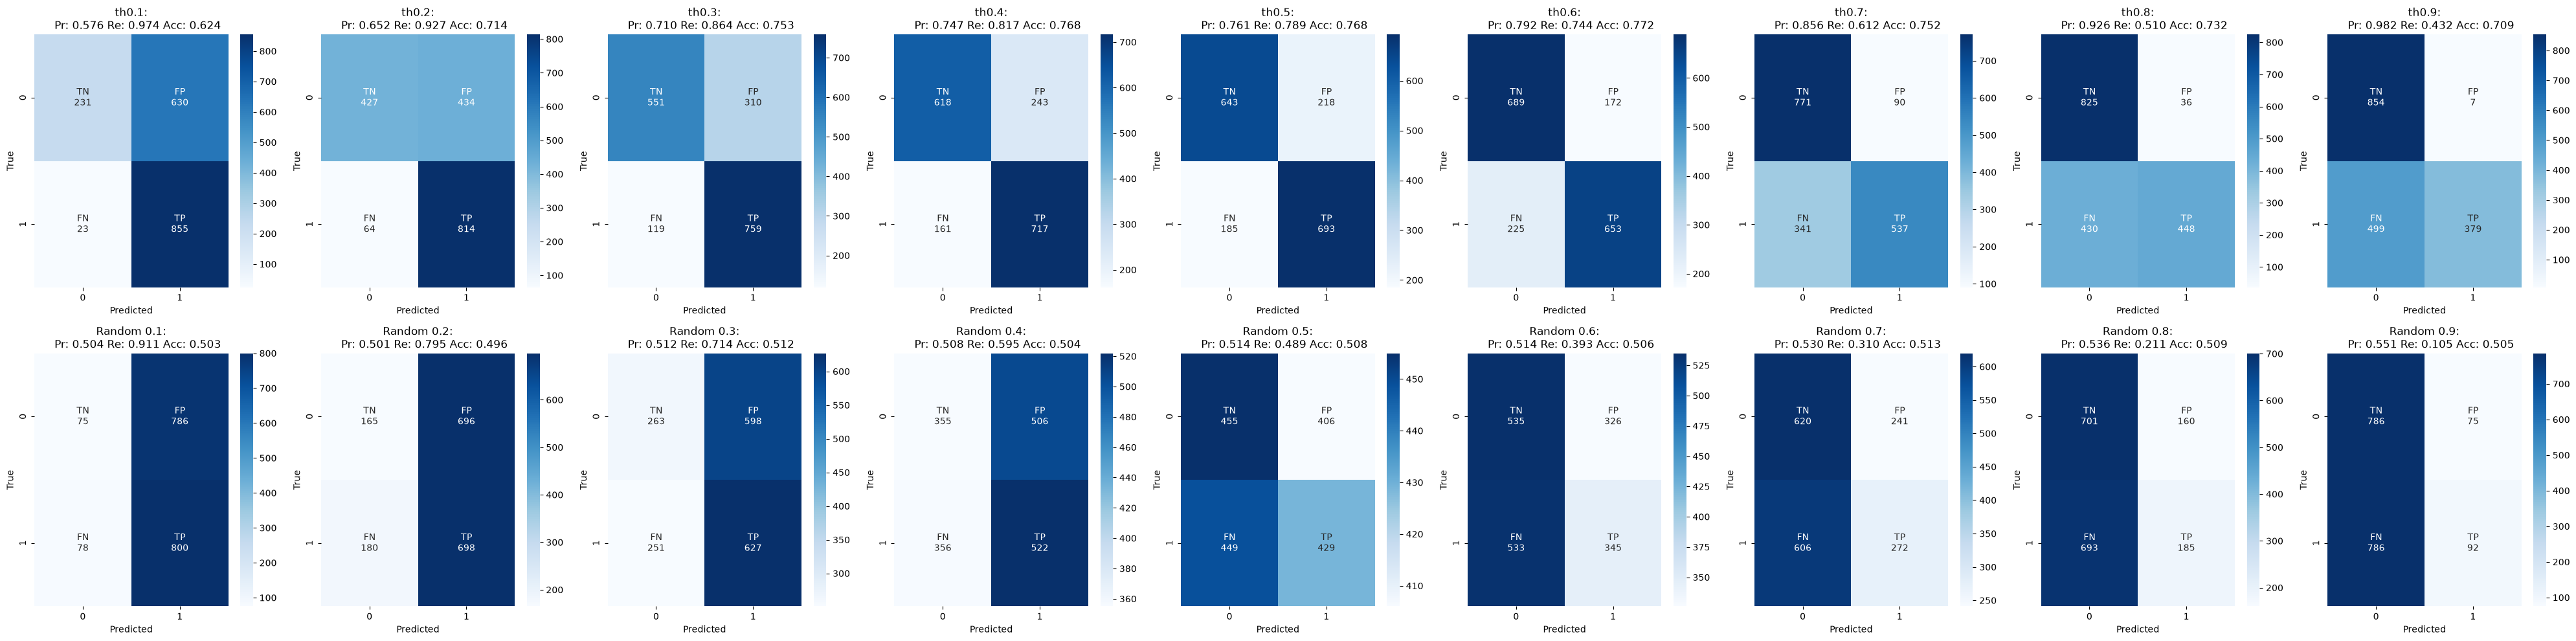

In [ ]:

fig, ax = plt.subplots(2, 9, figsize=(40, 10))
plot_confusion_matrix(y_test, df_th['th0.1'], ax[0, 0], "th0.1")
plot_confusion_matrix(y_test, df_th['th0.2'], ax[0, 1], "th0.2")
plot_confusion_matrix(y_test, df_th['th0.3'], ax[0, 2], "th0.3")
plot_confusion_matrix(y_test, df_th['th0.4'], ax[0, 3], "th0.4")
plot_confusion_matrix(y_test, df_th['th0.5'], ax[0, 4], "th0.5")
plot_confusion_matrix(y_test, df_th['th0.6'], ax[0, 5], "th0.6")
plot_confusion_matrix(y_test, df_th['th0.7'], ax[0, 6], "th0.7")
plot_confusion_matrix(y_test, df_th['th0.8'], ax[0, 7], "th0.8")
plot_confusion_matrix(y_test, df_th['th0.9'], ax[0, 8], "th0.9")

plot_confusion_matrix(y_test, df_th['rnd0.1'], ax[1, 0], "Random 0.1")
plot_confusion_matrix(y_test, df_th['rnd0.2'], ax[1, 1], "Random 0.2")
plot_confusion_matrix(y_test, df_th['rnd0.3'], ax[1, 2], "Random 0.3")
plot_confusion_matrix(y_test, df_th['rnd0.4'], ax[1, 3], "Random 0.4")
plot_confusion_matrix(y_test, df_th['rnd0.5'], ax[1, 4], "Random 0.5")
plot_confusion_matrix(y_test, df_th['rnd0.6'], ax[1, 5], "Random 0.6")
plot_confusion_matrix(y_test, df_th['rnd0.7'], ax[1, 6], "Random 0.7")
plot_confusion_matrix(y_test, df_th['rnd0.8'], ax[1, 7], "Random 0.8")
plot_confusion_matrix(y_test, df_th['rnd0.9'], ax[1, 8], "Random 0.9")
plt.tight_layout()
plt.savefig("confusion_matrices.png")

#### Precision-Recall Curve

In [ ]:
y_pred_rnd = np.random.rand(y_test.shape[0]) >= 0.5
from sklearn.metrics import confusion_matrix
cm_rnd = confusion_matrix(y_test, y_pred_rnd)
print("Random baseline confusion matrix:\n", cm_rnd)

Random baseline confusion matrix:
 [[429 432]
 [432 446]]


Precision-Recall thresholds: [0.         0.0625     0.06410256 0.06849315 0.07692308 0.08461538
 0.1        0.10344828 0.11111111 0.11538462 0.11904762 0.12371134
 0.125      0.13057325 0.18947368 0.19230769 0.2        0.2012987
 0.22222222 0.22916667 0.24137931 0.25396825 0.25675676 0.25925926
 0.27710843 0.28571429 0.28865979 0.29310345 0.31428571 0.3220339
 0.33333333 0.35789474 0.38235294 0.39506173 0.4        0.41414141
 0.44       0.45454545 0.48717949 0.5        0.50943396 0.53333333
 0.53846154 0.54347826 0.54545455 0.55       0.56666667 0.57142857
 0.58181818 0.60526316 0.60759494 0.60869565 0.61728395 0.61904762
 0.63157895 0.63636364 0.64957265 0.6557377  0.67582418 0.69230769
 0.7        0.7037037  0.71641791 0.74074074 0.74285714 0.74509804
 0.77941176 0.79166667 0.79310345 0.8021978  0.81395349 0.82608696
 0.83333333 0.88461538 0.88888889 0.92682927 0.9375     0.96226415
 0.97560976 0.97986577 0.98387097 1.        ]


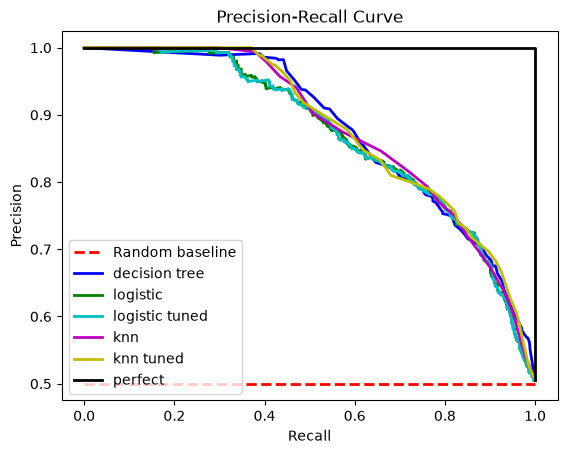

In [ ]:
# plot Precision-Recall curve for the tuned Decision Tree model
from sklearn.metrics import precision_recall_curve
y_prob_dt_tuned = model_dt_tuned.predict_proba(X_test)[:, 1]
y_prob_lr = model_lr.predict_proba(X_test)[:, 1]
y_prob_lr_tuned = model_lr_tuned.predict_proba(X_test)[:, 1]
y_prob_knn = model_knn.predict_proba(X_test)[:, 1]
y_prob_knn_tuned = model_knn_tuned.predict_proba(X_test)[:, 1]
y_prob_perfect = y_test
precision_dt_tuned, recall_dt_tuned, thresholds = precision_recall_curve(y_test, y_prob_dt_tuned)
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_prob_lr)
precision_lr_tuned, recall_lr_tuned, _ = precision_recall_curve(y_test, y_prob_lr_tuned)
precision_knn, recall_knn, _ = precision_recall_curve(y_test, y_prob_knn)
precision_knn_tuned, recall_knn_tuned, _ = precision_recall_curve(y_test, y_prob_knn_tuned)
precision_perfect, recall_perfect, _ = precision_recall_curve(y_test, y_prob_perfect)
print("Precision-Recall thresholds:", thresholds)
# random baseline for comparison
plt.plot([0, 1], [0.5, 0.5], color='r', lw=2, linestyle='--', label='Random baseline')
plt.plot(recall_dt_tuned, precision_dt_tuned, color='b', lw=2, label='decision tree')
plt.plot(recall_lr, precision_lr, color='g', lw=2, label='logistic')
plt.plot(recall_lr_tuned, precision_lr_tuned, color='c', lw=2, label='logistic tuned')
plt.plot(recall_knn, precision_knn, color='m', lw=2, label='knn')
plt.plot(recall_knn_tuned, precision_knn_tuned, color='y', lw=2, label='knn tuned')
plt.plot(recall_perfect, precision_perfect, color='k', lw=2, label='perfect')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

#### ROC Curve
$$
\text{TPR} = \frac{\text{TP}}{\text{TP} + \text{FN}}
$$
$$
\text{FPR} = \frac{\text{FP}}{\text{FP} + \text{TN}}
$$

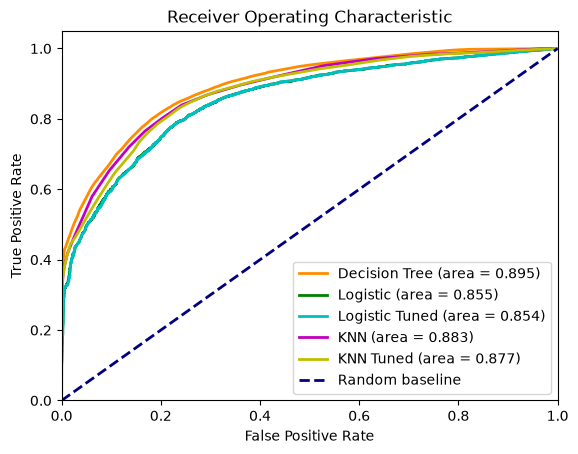

In [ ]:
# plot ROC curve for the tuned Decision Tree model
from sklearn.metrics import roc_curve, auc
y_prob_dt_tuned = model_dt_tuned.predict_proba(X)[:, 1]
y_prob_lr = model_lr.predict_proba(X)[:, 1]
y_prob_lr_tuned = model_lr_tuned.predict_proba(X)[:, 1]
y_prob_knn = model_knn.predict_proba(X)[:, 1]
y_prob_knn_tuned = model_knn_tuned.predict_proba(X)[:, 1]
fpr_lr, tpr_lr, thresholds_lr = roc_curve(y, y_prob_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)
fpr_lr_tuned, tpr_lr_tuned, thresholds_lr_tuned = roc_curve(y, y_prob_lr_tuned)
roc_auc_lr_tuned = auc(fpr_lr_tuned, tpr_lr_tuned)
fpr_knn, tpr_knn, thresholds_knn = roc_curve(y, y_prob_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)
fpr_knn_tuned, tpr_knn_tuned, thresholds_knn_tuned = roc_curve(y, y_prob_knn_tuned)
roc_auc_knn_tuned = auc(fpr_knn_tuned, tpr_knn_tuned)
fpr, tpr, thresholds = roc_curve(y, y_prob_dt_tuned)
roc_auc = auc(fpr, tpr)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='Decision Tree (area = %0.3f)' % roc_auc)
plt.plot(fpr_lr, tpr_lr, color='g', lw=2, label='Logistic (area = %0.3f)' % roc_auc_lr)
plt.plot(fpr_lr_tuned, tpr_lr_tuned, color='c', lw=2, label='Logistic Tuned (area = %0.3f)' % roc_auc_lr_tuned)
plt.plot(fpr_knn, tpr_knn, color='m', lw=2, label='KNN (area = %0.3f)' % roc_auc_knn)
plt.plot(fpr_knn_tuned, tpr_knn_tuned, color='y', lw=2, label='KNN Tuned (area = %0.3f)' % roc_auc_knn_tuned)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random baseline')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

### Prepare submission

In [ ]:
from datetime import datetime
from sklearn.base import clone

# After evaluation, refit the tuned pipeline on all labeled training rows.
# X and y include both parts of the earlier train/test split.
model_dt_tuned.fit(X, y)

df_test, df_train = pd.read_csv('test.csv'), pd.read_csv('train.csv')
df_train, df_test = prep_data_for_sub_kaggle_cheating(df_test, df_train)
df_test['Transported'] = model_lr_tuned.predict(df_test)
# df_test['Transported'] = model_dt_tuned.predict(df_test)
# df_test['Transported'] = model_knn_tuned.predict(df_test)
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
submission_path = f'submission_{timestamp}.csv'
df_test[['PassengerId', 'Transported']].to_csv(submission_path, index=False)
print(f"Trained on {len(y)} labeled rows. Saved {len(df_test)} predictions to {submission_path}.")

<class 'pandas.DataFrame'>
Index: 8693 entries, 0 to 8692
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8582 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8590 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  c_deck        8494 non-null   str    
 17  c_num         8494 non-null   str    
 18  c_side        8594 non-null   str    
 19  g

In [ ]:
# balagan
df_test = pd.read_csv("test.csv")
df_train = pd.read_csv("train.csv")
df_train[['group', 'num_in_group']] = df_train['PassengerId'].str.split('_', expand=True)
df_test[['group', 'num_in_group']] = df_test['PassengerId'].str.split('_', expand=True)

In [ ]:
df_test_groups_no_planet = \
    df_test[df_test['HomePlanet'].isna()]['group']
df_train_groups = df_train['group']

In [ ]:
def process(df_train, df_test):
    return df_train, df_test